In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

In [7]:
with open('victor-hugo-texts.txt', 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip() != '']

print(f"Exemple de texte: {texts[0]}")

Exemple de texte: Mes vers fuiraient


In [8]:
vocab_size = 1000
window_size = 3

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

In [13]:
X = []
y = []
for seq in sequences: 
    for i in range(1, len(seq)):
        start_index = max(0, i - window_size)
        X.append(seq[start_index:i])
        y.append(seq[i])

X = pad_sequences(X, maxlen=window_size, padding='pre')
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (11541, 3), y shape: (11541,)


In [14]:
embedding_dim = 16
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    SimpleRNN(32),
    Dense(vocab_size, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X, y, 
    epochs=500, 
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.0324 - loss: 6.1586
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0427 - loss: 5.8264
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0483 - loss: 5.7096
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0536 - loss: 5.5977
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0596 - loss: 5.4992
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0685 - loss: 5.4045
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0753 - loss: 5.3165
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0858 - loss: 5.2299
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0930 - loss: 5.1467
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0983 - loss: 5.0674
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1036 - loss: 4.9886
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

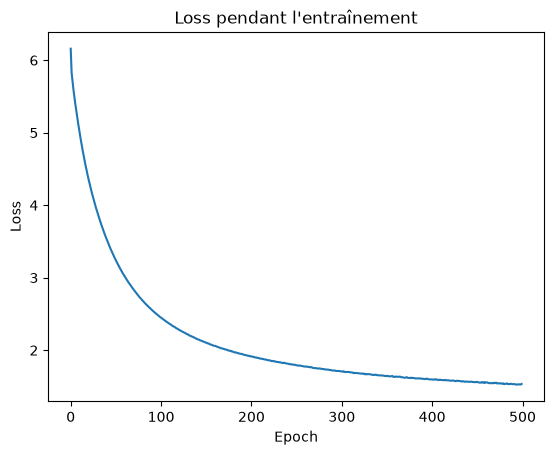

In [16]:
plt.plot(history.history['loss'])
plt.title('Loss pendant l\'entraînement')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [17]:
def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')

        probs = model.predict(tokens, verbose=0)[0]

        probs = np.exp(np.log(probs + 1e-9) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word =  tokenizer.index_word.get(index)
        if word is not None:
            text += ' ' + word
    return text

In [18]:
random_text = generate_text("Poème", num_words=50)
print(random_text)

Poème en chasse allons les » les les enfants ton doigt les champs son bout de les prés pour les murs aux les d'un des bois maint rose a seul de t plis pas se tombe prête une ne amour même ne pas elle dire en voir bas le bruit soufflant


In [19]:
from tensorflow.keras.layers import LSTM

embedding_dim = 16

model =  Sequential([
    Embedding(input_dim=vocab_size, output_dim= embedding_dim),
    LSTM(64),
    Dense(vocab_size, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [20]:
early_stop = EarlyStopping(
    monitor='loss',
    patience=10,
    restore_best_weights=True
)

history_lstm = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.0345 - loss: 6.1657
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0347 - loss: 5.8680
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0359 - loss: 5.8101
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0354 - loss: 5.7540
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0380 - loss: 5.7152
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0384 - loss: 5.6685
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0418 - loss: 5.6136
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0451 - loss: 5.5582
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0476 - loss: 5.5064
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0516 - loss: 5.4579
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0535 - loss: 5.4111
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

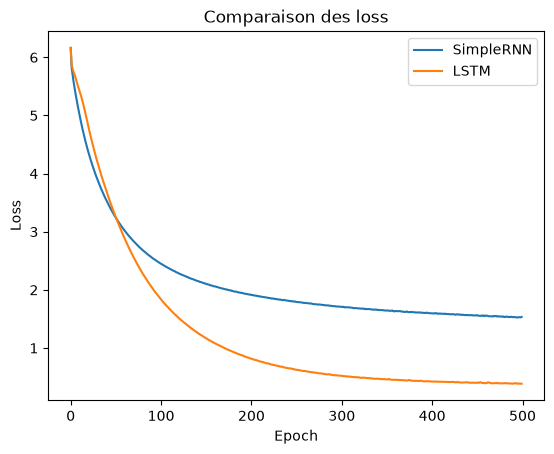

In [21]:
plt.plot(history.history["loss"], label="SimpleRNN")
plt.plot(history_lstm.history["loss"], label="LSTM")

plt.title("Comparaison des loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [22]:
print(generate_text("le poète", num_words=50, temperature=0.8))

le poète est divin déjà d'un enfant blanc parmi la la nuit tombe sabine un jour que tout était lumière vie et douceur pleins d'un rivage ou tout avec sur la brise sur la joie aux pieds souvenir des sans noir par la tempête et son avaient des trous la porte de


In [23]:
print("Température 0.3 :")
print(generate_text("le poète", num_words=50, temperature=0.3))

print("\nTempérature 0.8 :")
print(generate_text("le poète", num_words=50, temperature=0.8))

print("\nTempérature 1.2 :")
print(generate_text("le poète", num_words=50, temperature=1.2))

Température 0.3 :
le poète est divin sans tombe il dire le ciel bleu sur le vert en et toute être on eût un rire grêle et de morts les d'un sans la de leur du doigt la retire en frères amis que mes on est à votre porte il doute à boire et songe

Température 0.8 :
le poète en des jours vient des jours il est l'homme des bois ma meilleure pensée est pris de sa c'est l'heure voir s'il revient si la mer est meilleure s'il fait jour si la flamme est au du allons et la voilà qui part l'air ne pas rien voir d'un pas

Température 1.2 :
le poète seigneur de sa a son maudit où je va plus à la passer les » » et ces dans les plaines il noirs l'autre la pour nous fleurs parmi par comte soeur vos pieds monts sont vos flamme dans cette noir voici à j'ai sa bouche aux baisers l'oeil voilà


### Question 1 : Que fait Tokenizer et pourquoi est-il nécessaire avant un RNN ? 

Le Tokenizer transforme les mots d'un texte en identifiants numériques  
C'est nécessaire parce qu'un réseau de neurones ne peut pas traiter directement des mots sous forme de chaînes de caractères. Il travaille avec des nombres.

### Question 2 : Pourquoi utilise-t-on pad_sequences et que se passerait-il si on ne l'utilisait pas ?

pad_sequences permet de donner la même longueur à toutes les séquences.  
Sans cette opération, les séquences auraient des longueurs différentes et ne pourraient pas être regroupées directement dans un tableau de forme fixe pour l'entraînement du modèle.

### Question 3 : Quelle est la différence entre vocab_size et embedding_dim ? 

Vocab_size définit la taille du vocabulaire utilisé par le modèle.  
embedding_dim définit le nombre de dimensions utilisées pour représenter chaque mot, ici 16  
Chaque mot est représenté par un vecteur de x valeurs numériques (ici 16)

### Question 4 : En quoi consiste une couche Embedding, et pourquoi le place-t-on avant le RNN ? 

La couche Embedding transforme les identifiants numériques des mots en vecteurs de nombres appris pendant l'entraînement.  
Ces vecteurs permettent au réseau d'apprendre des représentations utiles des mots.  
On la place avant le RNN pour que celui-ci travaille sur ces représentations plutôt que sur de simples identifiants numériques.

### Question 5 : Quelle est la différence entre SimpleRNN et LSTM ? Dans quel cas préférer un LSTM ? 

Un SimpleRNN traite les mots les uns après les autres en conservant un état interne qui résume les informations précédentes   
Un LSTM fonctionne sur le même principe, mais possède un mécanisme de mémoire plus élaboré, avec des portes qui contrôlent les informations conservées ou oubliées.   
On privilégie généralement un LSTM lorsqu'il faut apprendre des dépendances sur des séquences plus longues.  

### Question 6 : Que représente window_size = 3 et comment influence-t-il l'apprentissage ? 

Cette variable définit le nombre maximal de mots précédent utilisés pour prédire le mot suivant.  
Une fenêtre plus grande permet d'utiliser d'avantage de contexte, mais rendrait l'apprentissage plus complexe.  
Avec seulement trois mots, le réseau dispose de peu d'informations pour produire un texte cohérent sur une longue durée.  

### Question 7 : Pourquoi utiliser sparse_categorical_crossentropy dans ce cas précis ? 

Cette fonction mesure l'erreur entre le mot prédit et le véritable mot attendu  
Chaque mot est représenté par un entier, et le modèle doit choisir parmi les identifiants du vocabulaire.  
La fonction sparse_categorical_crossentropy est adaptée à cette classification multiclasse lorsque les réponses attendues sont des entiers.  

### Question 8 : Que fait le callback EarlyStopping et pourquoi est-il utile ici ? 

EarlyStopping arrêt automatiquement l'entraînement lorsque la loss ne s'améliore plus pendant 10 époques consécutives.  
Cela évite de continuer inutilement jusqu'aux 500 époques prévues.  
Avec restore_best_weights=True, le modèle récupère les poids de l'époque ayant obtenu la meilleur loss surveillée.  

### Question 9 : En observant la courbe de la loss, comment savoir si le modèle converge bien ? 

Un modèle converge lorsque sa fonction de perte diminue progressivement puis tend à se stabiliser.   
Si la courbe descent puis se stabilise, cela indique que l'apprentissage progresse vers un minimum. Si elle reste élevée, oscille fortement ou augmente, le modèle peut rencontrer des difficultés d'apprentissage.  
Une loss faible sur l'entraînement ne garantit toutefois pas que le texte généré sera cohérent  

### Question 10 : Analyse le texte généré :  est-il grammaticalement correct et cohérent ? Pourquoi le modèle n'écrit-il pas encore comme Victor Hugo? 

Le texte généré par le LSTM n'est pas réellement cohérent, même s'il reprend des mots et des expressions issus du corpus d'entraînement   
On constate que le modèle parvient à reproduire certaines caractéristiques du vocabulaire, mais qu'il rencontre des difficultés à construire des phrases grammaticalement structurées et compréhensibles. On observe également des répétitions et des enchaînements de mots sans véritable logique.   
Ces limites peuvent notamment s'expliquer par la taille du corpus, la fenêtre de contexte limitée à trois mots et la méthode de génération probabiliste.   
Le modèle apprend donc certaines associations entre les mots, mais ne parvient pas encore à produire un texte cohérent comparable à celui d'un auteur.   